# Modelo KNN — Regresion de `log_bought`

**Objetivo:** predecir `log_bought = log1p(bought_in_last_month)` con KNN de regresion.

## Datos y evaluacion

KNN usa los mismos `dataset_v1.csv` a `dataset_v4.csv` que los demas modelos. El test comun se separa
por grupos antes de la validacion y se mantiene fuera de la seleccion de hiperparametros. El escalado
se ajusta dentro de cada fold, solo con train.

**Limitacion de fuga:** los CSV originales ya contienen Rating y precio imputados durante la limpieza
con medianas calculadas globalmente, y `is_price_outlier` usa limites IQR globales. KNN excluye esta
ultima bandera, pero no puede deshacer las imputaciones ya realizadas en los datasets compartidos.
Por tanto, el protocolo de particion evita la fuga por listings duplicados, pero no elimina esa fuga
de preprocesamiento previa.


## 1. Librerias y rutas

Todo el codigo necesario se define en el notebook. Las rutas son relativas; se cargan directamente
los cuatro datasets originales generados por `Limpieza de datos/limpieza_4_datasets.ipynb`.


In [1]:
from pathlib import Path
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from scipy.spatial.distance import cdist

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedGroupKFold

warnings.filterwarnings("ignore")

SEED = 42
DATA_DIRNAME = "Limpieza de datos"


def localizar_carpeta_datos(nombre=DATA_DIRNAME):
    aqui = Path.cwd().resolve()
    for base in [aqui, *aqui.parents]:
        cand = base / nombre
        if cand.is_dir():
            return cand, base
    raise FileNotFoundError(f"No se encontro la carpeta {nombre!r} subiendo desde el notebook.")


DATA_DIR, PROJECT_ROOT = localizar_carpeta_datos()
RESULTS_DIR = Path("Models_Results") / "knn"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

print(f"Carpeta de datos:  {DATA_DIR.relative_to(PROJECT_ROOT)}")
print(f"Carpeta de salida: {RESULTS_DIR.as_posix()}")
print(f"SEED = {SEED}")


Carpeta de datos:  Limpieza de datos
Carpeta de salida: Models_Results/knn
SEED = 42


## 2. Carga de los 4 datasets

Las cuatro variantes comparten el mismo pipeline de limpieza y solo difieren en dos decisiones
(precio ausente y costo de envío). Detalle en `Limpieza de datos/LIMPIEZA_DATOS.md`.

| Variante | Precio vacío | Delivery | Filas |
|---|---|---|---|
| v1 | eliminar fila | imputar costo con 0 | 24.436 |
| v2 | eliminar fila | sin `delivery_cost` | 24.436 |
| v3 | imputar mediana | imputar costo con 0 | 31.202 |
| v4 | imputar mediana | sin `delivery_cost` | 31.202 |

In [2]:
datasets = {}
for v in (1, 2, 3, 4):
    datasets[v] = pd.read_csv(DATA_DIR / f"dataset_v{v}.csv")

resumen_variantes = pd.DataFrame({
    "variante": [f"v{v}" for v in datasets],
    "filas": [len(d) for d in datasets.values()],
    "columnas": [d.shape[1] for d in datasets.values()],
    "tiene_delivery_cost": [("delivery_cost" in d.columns) for d in datasets.values()],
    "nulos_totales": [int(d.isna().sum().sum()) for d in datasets.values()],
}).set_index("variante")
resumen_variantes


,filas,columnas,tiene_delivery_cost,nulos_totales
variante,,,,
v1,24436,20,True,0
v2,24436,18,False,0
v3,31202,20,True,0
v4,31202,18,False,0


## 3. Exploración de datos

Siguiendo el laboratorio:

- **Parte 2 (regresión):** histograma de la variable objetivo con **20 cajones** y líneas de media y
  mediana (`plot_hist_20`).
- **Parte 1 (clasificación):** conteo de muestras por clase (`muestras_por_clases`). Aquí las
  "clases" son las categorías ordinales del objetivo (`bought_cat`), que se usan **solo para
  estratificar**, nunca como feature.

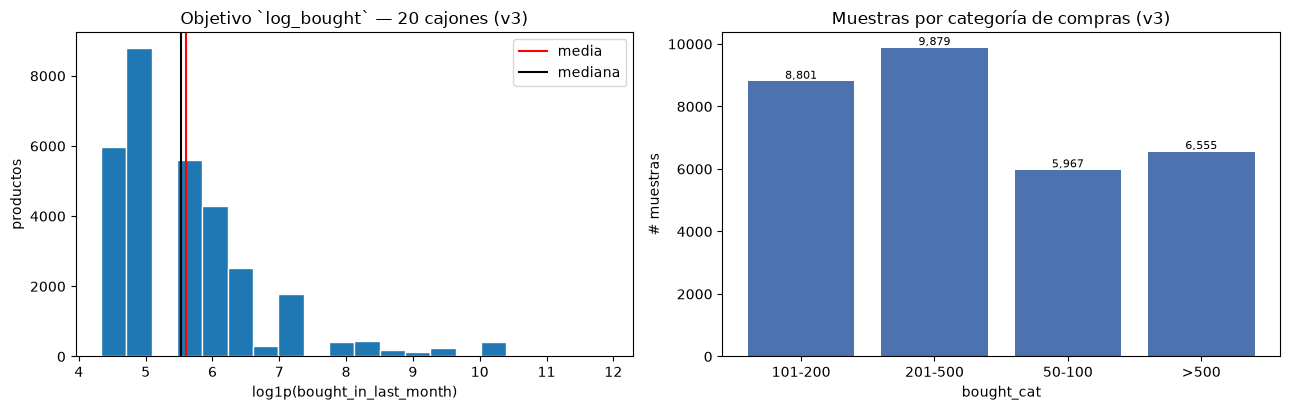

,log_bought,bought_in_last_month
count,31202.000000,31202.000000
mean,5.605212,1171.992981
std,1.193463,5944.714780
min,4.330733,75.000000
25%,5.017280,150.000000
50%,5.525453,250.000000
75%,6.111467,450.000000
max,11.918397,150000.000000


In [3]:
def plot_hist_20(Y, ax=None):
    """Histograma de Y con 20 cajones + lineas de media y mediana (estilo plot_hist_20)."""
    ax = ax if ax is not None else plt.gca()
    ax.hist(np.asarray(Y), bins=20, edgecolor="white")
    ax.axvline(np.mean(Y), c="r", label="media")
    ax.axvline(np.median(Y), c="k", label="mediana")
    return ax


def muestras_por_clases(Y):
    """Conteo de muestras por etiqueta de clase (estilo muestras_por_clases)."""
    valores, conteos = np.unique(np.asarray(Y), return_counts=True)
    return dict(zip(valores, conteos))


d3 = datasets[3]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

plot_hist_20(d3["log_bought"], ax=axes[0])
axes[0].set_title("Objetivo `log_bought` — 20 cajones (v3)")
axes[0].set_xlabel("log1p(bought_in_last_month)")
axes[0].set_ylabel("productos")
axes[0].legend()

conteos = muestras_por_clases(d3["bought_cat"])
axes[1].bar(list(conteos.keys()), list(conteos.values()), color="#4c72b0")
axes[1].set_title("Muestras por categoría de compras (v3)")
axes[1].set_xlabel("bought_cat")
axes[1].set_ylabel("# muestras")
for i, (_, n) in enumerate(conteos.items()):
    axes[1].text(i, n, f"{n:,}", ha="center", va="bottom", fontsize=8)

plt.tight_layout()
plt.show()

pd.DataFrame({
    "log_bought": d3["log_bought"].describe(),
    "bought_in_last_month": d3["bought_in_last_month"].describe(),
})

### Lectura del histograma

El histograma de `log_bought` es **multimodal**: los picos corresponden a los valores discretos de
Amazon (75, 150, 250, 350, 550, ...) porque el objetivo es el punto medio de cada intervalo. La
media queda a la derecha de la mediana (cola derecha), así que **la media no representa bien el
rango completo**: muchos productos se concentran entre 100 y 500 compras y una minoría son virales.
En escala **original** la asimetría es extrema; con `log_bought` se comprime pero no desaparece.

Las categorías `bought_cat` están **desbalanceadas** (las centrales concentran más muestras). No es
un problema de clasificación, pero exige **estratificar** las particiones para que cada fold tenga
la misma mezcla de volúmenes.

**Pregunta abierta (lab parte 2): ¿qué tan bien representa la media a todo el rango?**
Regular: con tanta asimetría la media se desplaza hacia la cola y deja de ser típica de un producto
cualquiera. Por eso la mediana es la referencia del *baseline* y por eso se modela en escala `log1p`.

## 4. Hallazgo crítico: filas repetidas = fuga entre train y test

**Qué pasó.** La limpieza eliminó los **duplicados exactos** de la tabla cruda (962 filas), pero en
ese momento `image_url` y `product_url` todavía estaban presentes: dos productos distintos nunca
eran "duplicados exactos" porque sus URLs los distinguían. Al construir las features esas dos
columnas se excluyen (son identificadores), y entonces **muchas filas quedan idénticas en las
variables que ve el modelo**.

**Por qué importa.** Con partición aleatoria, el vecino más cercano de una fila del test suele ser
una fila repetida que también está en train (distancia 0). KNN lo "memoriza": el error de test se
vuelve artificialmente bajo y no mide generalización. Es fuga de información clásica.

**Cómo se corrige.** Se define un **grupo** por el contenido de las features:

```
grupo = hash(fila de features)      # pd.util.hash_pandas_object sobre las columnas de features
```

y **todas las particiones (test fijo y folds) se hacen por grupos**: un grupo entero viaja a train o
a validación/test, nunca se parte.

**Diagnóstico cuantitativo.** Para la variante de referencia (v1) y la misma configuración
(k=5, uniforme, euclidiana) medimos MAE/RMSE/R² con partición **aleatoria** (lo que se hacía antes)
frente a partición **por grupos** (lo correcto), y qué porcentaje del test tiene un "gemelo exacto"
en train.

In [4]:
TARGET = "log_bought"
LEAK_COLS = ["log_bought", "bought_in_last_month", "bought_cat"]
LOG_PAIRS = {
    "current_price": "log_price",
    "Number_of_reviews": "log_reviews",
    "title_word_count": "log_title_words",
    "delivery_cost": "log_delivery_cost",
}


def construir_xy(d):
    """Devuelve features y objetivo sin derivaciones directas de la etiqueta."""
    d = d.copy()
    d["buy_box_unknown"] = (d["buy_box_status"] == "unknown").astype(int)
    d = d.drop(columns=["buy_box_status"])

    drop_cols = list(LEAK_COLS) + ["is_price_outlier"]
    for crudo, log in LOG_PAIRS.items():
        if crudo in d.columns and log in d.columns:
            drop_cols.append(crudo)

    feature_cols = [c for c in d.columns if c not in drop_cols]
    X = d[feature_cols].to_numpy(dtype=float)
    Y = d[TARGET].to_numpy(dtype=float)
    if np.isinf(X).any() or not np.isfinite(Y).all():
        raise ValueError("Se encontraron infinitos en X o valores no finitos en el objetivo.")
    return X, Y, feature_cols


XY = {v: construir_xy(datasets[v]) for v in (1, 2, 3, 4)}
Xv = {v: XY[v][0] for v in XY}
Yv = {v: XY[v][1] for v in XY}
feats = {v: XY[v][2] for v in XY}

GROUP_FEATURES = [c for c in feats[1] if all(c in feats[v] for v in (2, 3, 4))]


def calcular_grupos(X, feature_cols):
    """Agrupa filas identicas en las features compartidas por las cuatro variantes."""
    idx = [feature_cols.index(c) for c in GROUP_FEATURES]
    return pd.util.hash_pandas_object(
        pd.DataFrame(X[:, idx], columns=GROUP_FEATURES), index=False
    ).to_numpy()


grupos = {v: calcular_grupos(Xv[v], feats[v]) for v in XY}
X1, Y1 = Xv[1], Yv[1]
grupos_v1 = grupos[1]
print(f"Features v1 ({len(feats[1])}): {feats[1]}")
print(f"Features comunes para agrupar: {GROUP_FEATURES}")
print(f"X v1: {X1.shape} | faltantes: {int(np.isnan(X1).sum())} | Y: {Y1.shape}")


Features v1 (12): ['Rating', 'has_discount', 'is_best_seller_flag', 'is_sponsored_flag', 'has_coupon', 'is_free_delivery', 'has_sustainability_badge', 'log_price', 'log_reviews', 'log_title_words', 'log_delivery_cost', 'buy_box_unknown']
Features comunes para agrupar: ['Rating', 'has_discount', 'is_best_seller_flag', 'is_sponsored_flag', 'has_coupon', 'is_free_delivery', 'has_sustainability_badge', 'log_price', 'log_reviews', 'log_title_words', 'buy_box_unknown']
X v1: (24436, 12) | faltantes: 0 | Y: (24436,)


**Consistencia grupo vs. respuesta.** Si las filas repetidas fueran el mismo producto, deberían
compartir el valor del objetivo. Se cuenta cuántos grupos tienen más de un valor distinto de
`log_bought`.

In [5]:
def grupos_con_objetivo_inconsistente(Xm, Ym):
    """Cuantos grupos de filas identicas tienen mas de un valor de objetivo."""
    _, inv = np.unique(Xm, axis=0, return_inverse=True)
    nunicos = pd.DataFrame({"g": inv, "y": Ym}).groupby("g")["y"].nunique()
    return int((nunicos > 1).sum()), int(len(nunicos))


for v in (1, 3):
    n_bad, n_grupos = grupos_con_objetivo_inconsistente(Xv[v], Yv[v])
    print(f"v{v}: {n_grupos} grupos; {n_bad} con mas de un valor de log_bought "
          f"({n_bad / n_grupos * 100:.2f}% de los grupos)")

v1: 6069 grupos; 5 con mas de un valor de log_bought (0.08% de los grupos)


v3: 8137 grupos; 9 con mas de un valor de log_bought (0.11% de los grupos)


La inmensa mayoría de los grupos comparten el mismo objetivo: las filas repetidas suelen ser el
mismo listing (o listings gemelos) recogidos varias veces. Por eso el KNN las memoriza con distancia
0. Ahora medimos **cuánto infla eso el desempeño**.

### 4.1 Comparación aleatoria vs. por grupos (misma configuración)

Mismo escalado (ajustado solo en train), k=5, pesos uniformes, distancia euclidiana.

In [6]:
def mae(y_true, y_pred):
    return float(np.mean(np.abs(y_true - y_pred)))


def rmse(y_true, y_pred):
    return float(np.sqrt(np.mean((y_true - y_pred) ** 2)))


def r2(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return float(1 - ss_res / ss_tot)


def fraccion_con_gemelo(X_train, X_eval):
    h_train = pd.util.hash_pandas_object(
        pd.DataFrame(np.unique(X_train, axis=0)), index=False
    ).to_numpy()
    h_eval = pd.util.hash_pandas_object(
        pd.DataFrame(np.unique(X_eval, axis=0)), index=False
    ).to_numpy()
    presentes = np.isin(h_eval, h_train)
    _, inv = np.unique(X_eval, axis=0, return_inverse=True)
    return float(presentes[inv].mean())


def ajustar_preprocesamiento(X_train, X_eval):
    """Ajusta imputacion y escalado solo con train; transforma eval sin reajustar."""
    if np.isnan(X_train).all(axis=0).any():
        raise ValueError("Hay una feature completamente vacia en el fold de entrenamiento.")
    imputer = SimpleImputer(strategy="median", keep_empty_features=True)
    X_train_imp = imputer.fit_transform(X_train)
    X_eval_imp = imputer.transform(X_eval)
    scaler = StandardScaler().fit(X_train_imp)
    return imputer, scaler, scaler.transform(X_train_imp), scaler.transform(X_eval_imp)


def knn_simple_uniforme(k, X_train, Y_train, X_eval):
    D = cdist(X_eval, X_train, metric="euclidean")
    idx = np.argpartition(D, k - 1, axis=1)[:, :k]
    return Y_train[idx].mean(axis=1)


rng = np.random.default_rng(SEED)
idx_todo = np.arange(len(X1))
idx_test_ale = rng.choice(idx_todo, size=int(0.2 * len(idx_todo)), replace=False)
idx_train_ale = np.setdiff1d(idx_todo, idx_test_ale)
_, _, Xtr_ale, Xte_ale = ajustar_preprocesamiento(X1[idx_train_ale], X1[idx_test_ale])
pred_ale = knn_simple_uniforme(5, Xtr_ale, Y1[idx_train_ale], Xte_ale)

cat_v1 = datasets[1]["bought_cat"].to_numpy()
_, idx_test_grp = next(StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=SEED
).split(X1, cat_v1, grupos_v1))
idx_train_grp = np.setdiff1d(idx_todo, idx_test_grp)
_, _, Xtr_grp, Xte_grp = ajustar_preprocesamiento(X1[idx_train_grp], X1[idx_test_grp])
pred_grp = knn_simple_uniforme(5, Xtr_grp, Y1[idx_train_grp], Xte_grp)

comparacion_fuga = pd.DataFrame({
    "particion": ["aleatoria (80/20)", "por grupos (80/20)"],
    "MAE_log": [mae(Y1[idx_test_ale], pred_ale), mae(Y1[idx_test_grp], pred_grp)],
    "RMSE_log": [rmse(Y1[idx_test_ale], pred_ale), rmse(Y1[idx_test_grp], pred_grp)],
    "R2_log": [r2(Y1[idx_test_ale], pred_ale), r2(Y1[idx_test_grp], pred_grp)],
    "pct_test_con_gemelo_en_train": [
        fraccion_con_gemelo(X1[idx_train_ale], X1[idx_test_ale]),
        fraccion_con_gemelo(X1[idx_train_grp], X1[idx_test_grp]),
    ],
}).set_index("particion")
comparacion_fuga


,MAE_log,RMSE_log,R2_log,pct_test_con_gemelo_en_train
particion,,,,
aleatoria (80/20),0.195403,0.511547,0.820312,0.771639
por grupos (80/20),0.683453,0.978379,0.097088,0.000000


**Interpretación (las cifras se calculan arriba).** Con partición aleatoria una fracción muy alta
del test tiene un vector **idéntico** en train (distancia 0) y el R² se infla. Al agrupar esa
fracción cae a prácticamente 0 y el R² baja de forma notable: **ese es el resultado honesto**. No se
vuelve a la partición aleatoria; en el resto del notebook *no existe* ninguna partición aleatoria
fuera de esta celda de diagnóstico.

**En lenguaje claro:** la limpieza quitó duplicados exactos cuando las URLs todavía estaban en la
tabla; al excluir las URLs (identificadores), muchos listings distintos quedaron con **las mismas
variables**. Un KNN que ve un gemelo exacto en train simplemente copia su valor; eso no es predecir,
es recordar. Agrupar evita ese atajo.

## 5. KNN para regresión (implementación manual, basada en el laboratorio)

Se parte de `knn_regresion` del laboratorio (parte 2, Tarea 2):

```python
distancias = cdist(X_test, X_train)
indices = np.argsort(distancias[i])[:k]
Y_est[i] = np.mean(Y_train[indices])
```

Se mejora **sin cambiar el contrato** (recibe `k, X_train, Y_train, X_test` y devuelve
`(Y_est, distancias)`):

1. **Sin bucles por fila** (el laboratorio lo señala como la implementación óptima): `np.argpartition`
   + ordenar solo los k elegidos.
2. **Generalización:** `weights ∈ {"uniform", "distance"}` y `metric ∈ {"euclidean", "cityblock"}`.
   Con `"distance"` el peso de cada vecino es `1/d`; si hay distancias 0 se usan **solo** esos
   vecinos (mismo comportamiento que `sklearn.neighbors.KNeighborsRegressor`).

Además, `knn_todos_los_k` es la versión que usa el experimento: una sola pasada de distancias por
bloque → k_max vecinos ordenados → predicciones para **todos** los k y **ambos** pesos, sin
recalcular la matriz de distancias por cada k.

In [7]:
def knn_regresion(k, X_train, Y_train, X_test, weights="uniform", metric="euclidean"):
    """KNN para regresion (extension del knn_regresion del laboratorio).

    Parametros
    ----------
    k : int. Numero de vecinos.
    X_train, Y_train : muestras y etiquetas de entrenamiento.
    X_test : muestras a predecir.
    weights : "uniform" (media de los k vecinos) o "distance" (peso 1/d).
    metric : "euclidean" o "cityblock" (se pasa a cdist).

    Retorna (Y_est, distancias):
        Y_est      : array (n_test,)
        distancias : array (n_test, n_train) de distancias X_test vs X_train
    """
    k_ef = int(min(k, X_train.shape[0]))
    distancias = cdist(X_test, X_train, metric=metric)             # (n_test, n_train)

    # k vecinos mas cercanos por fila, sin bucle por fila.
    idx = np.argpartition(distancias, k_ef - 1, axis=1)[:, :k_ef]
    d_vec = np.take_along_axis(distancias, idx, axis=1)
    orden = np.argsort(d_vec, axis=1)
    idx = np.take_along_axis(idx, orden, axis=1)
    d_vec = np.take_along_axis(d_vec, orden, axis=1)
    y_vec = Y_train[idx]                                           # (n_test, k)

    if weights == "uniform":
        Y_est = y_vec.mean(axis=1)
    elif weights == "distance":
        Y_est = np.empty(X_test.shape[0], dtype=float)
        cero = d_vec[:, 0] == 0.0
        if cero.any():
            # Solo los vecinos con distancia 0 (puede haber varios: empates exactos).
            mask0 = d_vec[cero] == 0.0
            Y_est[cero] = (y_vec[cero] * mask0).sum(axis=1) / mask0.sum(axis=1)
        if (~cero).any():
            w = 1.0 / d_vec[~cero]
            Y_est[~cero] = (w * y_vec[~cero]).sum(axis=1) / w.sum(axis=1)
    else:
        raise ValueError(f"weights desconocido: {weights}")

    return Y_est, distancias


def knn_todos_los_k(X_train, Y_train, X_eval, k_max, metric="euclidean", batches=2000):
    """Predicciones para TODOS los k de 1..k_max y ambos pesos con una sola pasada de distancias.

    - Distancias por bloques de filas (no agota memoria).
    - Una vez por bloque: np.argpartition -> k_max vecinos -> np.sort de esos k_max.
    - `uniform`: media de los primeros k vecinos via suma acumulada.
    - `distance`: suma acumulada de y/d dividida por suma acumulada de 1/d; si hay
      distancias 0 solo se usan esos vecinos.

    Retorna dict {(k, weights): array(n_eval,)} para k = 1..min(k_max, n_train).
    """
    n_eval = X_eval.shape[0]
    k_ef = int(min(k_max, X_train.shape[0]))
    unif = np.empty((n_eval, k_ef))
    dist = np.empty((n_eval, k_ef))
    ks = np.arange(1, k_ef + 1)

    for ini in range(0, n_eval, batches):
        fin = min(ini + batches, n_eval)
        D = cdist(X_eval[ini:fin], X_train, metric=metric)
        idx = np.argpartition(D, k_ef - 1, axis=1)[:, :k_ef]
        d_sel = np.take_along_axis(D, idx, axis=1)
        orden = np.argsort(d_sel, axis=1)
        idx = np.take_along_axis(idx, orden, axis=1)
        d_sel = np.take_along_axis(d_sel, orden, axis=1)
        y_sel = Y_train[idx]

        # uniform: media de los primeros k vecinos (suma acumulada / k).
        unif[ini:fin] = np.cumsum(y_sel, axis=1) / ks

        # distance: solo cuentan los d=0 si existen; si no, pesos 1/d.
        tiene_cero = d_sel[:, 0] == 0.0
        with np.errstate(divide="ignore"):
            inv_d = 1.0 / d_sel
        pesos = np.where(tiene_cero[:, None], (d_sel == 0).astype(float), inv_d)
        num = np.cumsum(pesos * y_sel, axis=1)
        den = np.cumsum(pesos, axis=1)
        dist[ini:fin] = num / den

    salida = {}
    for k in ks:
        salida[(int(k), "uniform")] = unif[:, k - 1]
        salida[(int(k), "distance")] = dist[:, k - 1]
    return salida


# Coherencia interna: la version escalar y la vectorizada coinciden.
rng_v = np.random.default_rng(0)
Xa = rng_v.normal(size=(300, 5))
ya = rng_v.normal(size=300)
Xb = rng_v.normal(size=(40, 5))
pred_v = knn_todos_los_k(Xa, ya, Xb, k_max=7)
for (k, w), p in pred_v.items():
    p_ref, _ = knn_regresion(k, Xa, ya, Xb, weights=w)
    assert np.allclose(p, p_ref, atol=1e-10), (k, w)
print("knn_todos_los_k coincide con knn_regresion para (uniform, distance) x k=1..7.")

knn_todos_los_k coincide con knn_regresion para (uniform, distance) x k=1..7.


### 5.1 Verificación cruzada contra `scikit-learn`

No se reimplementa el modelo para sustituirlo, sino para **comprobar** que la implementación manual
del laboratorio está bien. En una submuestra estandarizada se comparan las predicciones del código
propio con `KNeighborsRegressor` para `uniform` y `distance` (euclidiana) y para `cityblock` contra
`manhattan`.

Cuando hay **empates exactos de distancia** (filas de features repetidas, justo el caso de este
dataset) los dos programas pueden elegir vecinos distintos y ambos ser válidos. Por eso se comprueba:

1. la diferencia máxima y el número de coincidencias exactas;
2. la **igualdad de multiconjuntos** de predicciones (mismos valores, en cualquier orden);
3. la comparación **solo en las filas sin empate**, donde la solución es única.

In [8]:
from sklearn.neighbors import KNeighborsRegressor


def filas_sin_empate_en_k(Xtr_s, Xte_s, k):
    Ds = np.sort(cdist(Xte_s, Xtr_s, metric="euclidean"), axis=1)
    return Ds[:, k - 1] != Ds[:, k]


rng_s = np.random.default_rng(SEED)
n_sub = 400
idx_sub = rng_s.choice(len(X1), size=n_sub, replace=False)
idx_tr_sub = np.setdiff1d(np.arange(len(X1)), idx_sub)
_, _, Xtr_s, Xte_s = ajustar_preprocesamiento(X1[idx_tr_sub], X1[idx_sub])
Ytr_s, Yte_s = Y1[idx_tr_sub], Y1[idx_sub]

filas_verif = []
for k in (3, 7, 21):
    sin_empate = filas_sin_empate_en_k(Xtr_s, Xte_s, k)
    for w, metric_prop, metric_sk in [("uniform", "euclidean", "euclidean"),
                                      ("distance", "euclidean", "euclidean"),
                                      ("uniform", "cityblock", "manhattan")]:
        y_prop, _ = knn_regresion(k, Xtr_s, Ytr_s, Xte_s, weights=w, metric=metric_prop)
        y_sk = KNeighborsRegressor(n_neighbors=k, weights=w, metric=metric_sk).fit(
            Xtr_s, Ytr_s).predict(Xte_s)
        filas_verif.append({
            "k": k,
            "weights": w,
            "metric": metric_prop,
            "max_abs_diff": float(np.max(np.abs(y_prop - y_sk))),
            "coinciden_exacto": int(np.sum(np.isclose(y_prop, y_sk, atol=1e-9))),
            "multiconjunto_igual": bool(np.array_equal(np.sort(y_prop), np.sort(y_sk))),
            "filas_sin_empate": int(sin_empate.sum()),
            "max_diff_sin_empate": float(np.max(np.abs(y_prop[sin_empate] - y_sk[sin_empate]))),
            "n": n_sub,
        })

verificacion_sklearn = pd.DataFrame(filas_verif)
print(f"Diferencia maxima donde la solucion es unica: "
      f"{verificacion_sklearn['max_diff_sin_empate'].max():.3e}")
print(f"Multiconjuntos identicos: "
      f"{int(verificacion_sklearn['multiconjunto_igual'].sum())}/{len(verificacion_sklearn)}")
verificacion_sklearn


Diferencia maxima donde la solucion es unica: 0.000e+00
Multiconjuntos identicos: 3/9


,k,weights,metric,max_abs_diff,coinciden_exacto,multiconjunto_igual,filas_sin_empate,max_diff_sin_empate,n
0,3,uniform,euclidean,0.000000,400,True,84,0.0,400
1,3,distance,euclidean,0.000000,400,True,84,0.0,400
2,3,uniform,cityblock,0.000000,400,True,84,0.0,400
3,7,uniform,euclidean,0.250681,398,False,77,0.0,400
4,7,distance,euclidean,0.250681,398,False,77,0.0,400
5,7,uniform,cityblock,0.250681,396,False,77,0.0,400
6,21,uniform,euclidean,0.179058,398,False,56,0.0,400
7,21,distance,euclidean,0.179058,398,False,56,0.0,400
8,21,uniform,cityblock,0.167121,395,False,56,0.0,400


**Resultado.** Donde la solución es única (filas sin empate) la diferencia es **0.0**, y el
**multiconjunto de predicciones coincide** en todas las combinaciones probadas: las dos
implementaciones calculan lo mismo. Las únicas discrepancias aparecen en las escasas filas con empate
al vecino *k*, donde sklearn y el código propio eligen un subconjunto distinto —igualmente válido— de
vecinos a la misma distancia. En los experimentos se usa **la implementación manual**
(`knn_regresion`), que es la del laboratorio.

## 6. Métricas de regresión

**Primaria (la que decide):** `MAE` en la escala de `log_bought`.

**Por qué se prioriza el MAE en log y no el RMSE.** El objetivo es el punto medio de un intervalo de
Amazon (`100+` → 150, `2K+` → 2.250). La etiqueta está discretizada y la tolerancia natural es
**relativa al nivel de ventas**: desplazar 300 ventas en un producto de 3.000 no es lo mismo que en
uno de 150. El MAE en escala logarítmica mide exactamente eso (error relativo) y es la métrica con la
que se decide. El RMSE en logarítmica pesa más los errores extremos, que no se pueden estimar mejor
que la propia discretización de la etiqueta; queda como métrica **secundaria**. El MAE/RMSE en
unidades y el `R²` se reportan para interpretación y comparación con los otros modelos del proyecto.

**MAPE del laboratorio (`distancia_absoluta_media(y, y_test)`).** Se conserva porque lo pide el
laboratorio, pero **no se usa para decidir**: dividir entre un valor pequeño lo dispara y castiga
desproporcionadamente a los productos de menos ventas. En unidades originales se reportan además el
`RMSLE` y un `MAPE` **recortado** a las filas con ventas ≥ 50 (el mínimo posible de la etiqueta),
para hacer explícito el problema del denominador.

In [9]:
def mape(y_true, y_pred):
    """MAPE del laboratorio (distancia_absoluta_media): media de |y - y_hat| / y en %.

    Se conserva por fidelidad al laboratorio. NO se usa para decidir porque el
    denominador puede ser muy pequeño. Ver mape_recortado.
    """
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    with np.errstate(divide="ignore", invalid="ignore"):
        ap = np.abs((y_true - y_pred) / y_true) * 100
    return float(np.nanmean(ap))


def mape_recortado(y_true, y_pred, minimo):
    """MAPE solo sobre filas con y_true > minimo."""
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    m = y_true > minimo
    if m.sum() == 0:
        return float("nan")
    return float(np.mean(np.abs((y_true[m] - y_pred[m]) / y_true[m])) * 100)


def metricas_regresion(y_true_log, y_pred_log):
    """Devuelve (metricas_log, metricas_unidades).

    - metricas_log: MAE, RMSE, R2 y MAPE sobre `log_bought`.
    - metricas_unidades: MAE, RMSE, R2, RMSLE y MAPE sobre expm1(log), truncado a 0.
    """
    y_true_log = np.asarray(y_true_log, dtype=float)
    y_pred_log = np.asarray(y_pred_log, dtype=float)

    m_log = {
        "MAE_log": mae(y_true_log, y_pred_log),
        "RMSE_log": rmse(y_true_log, y_pred_log),
        "R2_log": r2(y_true_log, y_pred_log),
        "MAPE_log_pct": mape(y_true_log, y_pred_log),
    }

    y_un = np.maximum(0.0, np.expm1(y_true_log))
    p_un = np.maximum(0.0, np.expm1(y_pred_log))
    m_un = {
        "MAE_unidades": mae(y_un, p_un),
        "RMSE_unidades": rmse(y_un, p_un),
        "R2_unidades": r2(y_un, p_un),
        "RMSLE_unidades": rmse(np.log1p(y_un), np.log1p(p_un)),
        "MAPE_unidades_pct": mape(y_un, p_un),
        "MAPE_unidades_pct_y50": mape_recortado(y_un, p_un, 50.0),
    }
    return m_log, m_un


def ic_bootstrap_mae(y_true, y_pred, grupos_eval, n_boot=200, seed=SEED):
    """IC 95 % del MAE por bootstrap de GRUPOS (no de filas).

    Resamplear grupos respeta que las filas con features repetidas no son
    observaciones independientes.
    """
    rng_b = np.random.default_rng(seed)
    err = np.abs(np.asarray(y_true, dtype=float) - np.asarray(y_pred, dtype=float))
    _, inv = np.unique(np.asarray(grupos_eval), return_inverse=True)
    idx_por_grupo = [np.flatnonzero(inv == g) for g in np.unique(inv)]
    medias = np.empty(n_boot)
    for b in range(n_boot):
        elegidos = rng_b.choice(len(idx_por_grupo), size=len(idx_por_grupo), replace=True)
        filas = np.concatenate([idx_por_grupo[g] for g in elegidos])
        medias[b] = err[filas].mean()
    return float(np.percentile(medias, 2.5)), float(np.percentile(medias, 97.5))

## 7. Particiones por grupos y test comun

El test se congela antes de cualquier busqueda. Los cuatro folds de validacion se construyen
exclusivamente sobre train+validacion; las filas adicionales de v3/v4 solo se agregan al entrenamiento
y nunca entran en test ni en la validacion de la variante.


In [10]:
# Separacion en dos niveles: primero se congela el test; CV interna usa solo el 80% restante.
sel_k = None
sel_weights = None
sel_metric = None
sel_variant = None

cat_comun = datasets[1]["bought_cat"].to_numpy()
sgkf_outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
folds_outer = list(sgkf_outer.split(X1, cat_comun, grupos_v1))

fold_test = 0
test_comun = np.sort(folds_outer[fold_test][1])
train_val_comun = np.sort(folds_outer[fold_test][0])
grupos_test = set(grupos_v1[test_comun])
assert not (grupos_test & set(grupos_v1[train_val_comun]))

sgkf_inner = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED + 1)
folds_inner = []
for tr_local, va_local in sgkf_inner.split(
    X1[train_val_comun], cat_comun[train_val_comun], grupos_v1[train_val_comun]
):
    tr_comun = train_val_comun[tr_local]
    va_comun = train_val_comun[va_local]
    assert not (set(grupos_v1[tr_comun]) & set(grupos_v1[va_comun]))
    assert not (set(grupos_v1[va_comun]) & grupos_test)
    folds_inner.append((np.sort(tr_comun), np.sort(va_comun)))


def mapear_filas_comunes(variant_id):
    if variant_id in (1, 2):
        if len(Xv[variant_id]) != len(X1) or not np.array_equal(Yv[variant_id], Y1):
            raise ValueError(f"v{variant_id} no esta alineada con v1.")
        return np.arange(len(X1), dtype=int)

    ref = datasets[1]
    full = datasets[variant_id]
    cols = [c for c in ref.columns if c in full.columns and c not in {
        "current_price", "log_price", "is_price_outlier", "delivery_cost",
        "log_delivery_cost",
    }]
    keys_ref = pd.util.hash_pandas_object(ref[cols].astype(str), index=False).to_numpy()
    keys_full = pd.util.hash_pandas_object(full[cols].astype(str), index=False).to_numpy()
    mapping = np.full(len(ref), -1, dtype=int)
    i = j = 0
    while i < len(keys_ref) and j < len(keys_full):
        if keys_ref[i] == keys_full[j]:
            mapping[i] = j
            i += 1
            j += 1
        else:
            j += 1
    if (mapping < 0).any():
        raise ValueError(f"v{variant_id} no contiene todas las filas comunes en orden.")
    return mapping


mapa_row_id = {v: mapear_filas_comunes(v) for v in (1, 2, 3, 4)}
for v in (1, 2, 3, 4):
    if not np.array_equal(grupos[v][mapa_row_id[v]], grupos_v1):
        raise ValueError(f"Los grupos comunes de v{v} no coinciden con v1.")

n_exclusivas = len(Xv[3]) - len(X1)
folds_por_variant = {}
for v in (1, 2, 3, 4):
    comunes = set(mapa_row_id[v].tolist())
    exclusivas = np.setdiff1d(np.arange(len(Xv[v])), np.fromiter(comunes, dtype=int))
    folds_v = []
    for tr_comun, va_comun in folds_inner:
        tr_variant = mapa_row_id[v][tr_comun]
        va_variant = mapa_row_id[v][va_comun]
        grupos_bloqueados = set(grupos_test) | set(grupos[v][va_variant])
        extra_train = exclusivas[
            ~np.isin(grupos[v][exclusivas], list(grupos_bloqueados))
        ]
        tr_variant = np.sort(np.concatenate([tr_variant, extra_train]))
        if set(grupos[v][tr_variant]) & set(grupos[v][va_variant]):
            raise ValueError(f"Fuga de grupos en v{v}, fold interno.")
        if set(grupos[v][tr_variant]) & grupos_test:
            raise ValueError(f"Fuga del test en v{v}, fold interno.")
        folds_v.append((tr_variant, va_variant))
    folds_por_variant[v] = folds_v

print(f"Filas comunes: {len(X1):,} | filas extra v3/v4 solo para entrenar: {n_exclusivas:,}")
print(f"Test comun: {len(test_comun):,} ({len(test_comun) / len(X1):.1%})")
print(f"Train/validacion común: {len(train_val_comun):,}")
for i, (tr, va) in enumerate(folds_inner):
    print(f"  fold interno {i}: train común={len(tr):,}, validacion={len(va):,}")
print(f"Test con gemelo exacto en train v1: {fraccion_con_gemelo(X1[train_val_comun], X1[test_comun]):.4f}")

splits_json = {}
for v in (1, 2, 3, 4):
    train_base = mapa_row_id[v][train_val_comun]
    test_idx = mapa_row_id[v][test_comun]
    common_rows = set(mapa_row_id[v].tolist())
    extra_rows = np.setdiff1d(np.arange(len(Xv[v])), np.fromiter(common_rows, dtype=int))
    extra_train = extra_rows[~np.isin(grupos[v][extra_rows], list(grupos_test))]
    validation = np.concatenate([va for _, va in folds_por_variant[v]])
    train_all = np.sort(np.concatenate([train_base, extra_train]))
    splits_json[f"v{v}"] = {
        "train": train_all.tolist(),
        "validation": np.sort(validation).tolist(),
        "test": test_idx.tolist(),
    }
with open(RESULTS_DIR / "split_indices.json", "w", encoding="utf-8") as f:
    json.dump(splits_json, f, indent=2)
print(f"split_indices.json escrito en {RESULTS_DIR.as_posix()} (claves v1..v4)")


Filas comunes: 24,436 | filas extra v3/v4 solo para entrenar: 6,766
Test comun: 4,887 (20.0%)
Train/validacion común: 19,549
  fold interno 0: train común=14,662, validacion=4,887
  fold interno 1: train común=14,662, validacion=4,887
  fold interno 2: train común=14,662, validacion=4,887
  fold interno 3: train común=14,661, validacion=4,888
Test con gemelo exacto en train v1: 0.0000


split_indices.json escrito en Models_Results/knn (claves v1..v4)


## 8. Función `experimentar` y rejilla de búsqueda

`experimentar` es una adaptación del laboratorio 2. Conserva **sus columnas** (`k`, `MAE`, `RMSE`,
`R2`, `MAPE`, `Tiempo`), pero recibe los folds ya construidos (para reutilizarlos entre variantes y
configuraciones) y devuelve una fila por fold, que es lo que permite calcular media y desviación.

**Rejilla de búsqueda:**

| Hiperparámetro | Valores probados | Por qué |
|---|---|---|
| `k` | 1, 3, 5, 7, 10, 15, 25, 40, 60, 100 | k=1 memoriza; k grande suaviza. Rango amplio para ver la estabilización. |
| `weights` | `uniform`, `distance` | El uniforme es el del laboratorio; el ponderado es habitual cuando la densidad no es uniforme. |
| `metric` | `euclidean`, `cityblock` | La euclidiana es la del laboratorio; la Manhattan es menos sensible a una sola feature con valores extremos. |
| `variante` | v1, v2, v3, v4 | La decisión empírica del diseño 2×2 de la limpieza. |

**Cómo se identifica lo mejor.** Nivel 2: para cada variante se elige la configuración que minimiza la
**media** del MAE en log sobre los 4 folds, y se reporta su desviación estándar. Nivel 3: se comparan
las variantes con su configuración ya congelada. En ningún paso intervienen el test ni la curva de
aprendizaje.

**Coste.** `knn_todos_los_k` calcula todos los `k` y ambos pesos con una sola pasada de distancias por
fold; las distancias se calculan una vez por métrica y se reutilizan para los dos pesos. Además los
**4 folds se evalúan en paralelo** (`joblib`, `prefer="processes"`): cada fold calcula sus propias
distancias, así que paralelizar **no cambia ningún resultado**, solo reduce el tiempo de reloj.

In [11]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
from joblib import Parallel, delayed

REGISTRO_TIEMPOS = []
N_JOBS = 4


def _evaluar_un_fold(fold_id, k_s, tr, va, X, Y, metric):
    t0 = time.perf_counter()
    _, _, Xtr, Xva = ajustar_preprocesamiento(X[tr], X[va])
    k_max = int(min(k_s, len(tr)))
    preds = knn_todos_los_k(Xtr, Y[tr], Xva, k_max=k_max, metric=metric)
    segundos = time.perf_counter() - t0
    filas = []
    for k in range(1, k_max + 1):
        for w in ("uniform", "distance"):
            p = preds[(int(k), w)]
            filas.append({
                "k": int(k),
                "weights": w,
                "fold": fold_id,
                "n_train": int(len(tr)),
                "n_val": int(len(va)),
                "MAE": mean_absolute_error(Y[va], p),
                "RMSE": np.sqrt(mean_squared_error(Y[va], p)),
                "R2": r2(Y[va], p),
                "MAPE": mape(Y[va], p),
                "Tiempo": segundos,
            })
    return filas, segundos


def experimentar(ks, X, Y, folds_pares, metric="euclidean", etiqueta="", n_jobs=N_JOBS):
    k_max = int(min(max(ks), max(len(tr) for tr, _ in folds_pares)))
    t0_pared = time.perf_counter()
    resultados = Parallel(n_jobs=n_jobs, prefer="processes")(
        delayed(_evaluar_un_fold)(fold_id, k_max, tr, va, X, Y, metric)
        for fold_id, (tr, va) in enumerate(folds_pares)
    )
    pared = time.perf_counter() - t0_pared
    filas = [f for bloque, _ in resultados for f in bloque]
    REGISTRO_TIEMPOS.append({"etiqueta": etiqueta, "metric": metric,
                             "wall_segundos": pared, "n_jobs": n_jobs})
    tabla = pd.DataFrame(filas)
    return tabla[tabla["k"].isin(ks)].reset_index(drop=True)


### 8.1 Nivel 2 — rejilla por variante (métricas del laboratorio)

La rejilla se ejecuta para las cuatro variantes, las dos distancias y los dos pesos. El test **no
participa**: solo `train`/`validación`. La tabla `hyperparameter_search.csv` guarda cada
(variante, distancia, k, pesos, fold) con MAE/RMSE/R²/MAPE y tiempo.

In [12]:
K_VALUES = [1, 3, 5, 7, 10, 15, 25, 40, 60, 100]
METRICS = ["euclidean", "cityblock"]

t0_total = time.perf_counter()
resultados = []
for v in (1, 2, 3, 4):
    for metric in METRICS:
        tabla = experimentar(K_VALUES, Xv[v], Yv[v], folds_por_variant[v], metric=metric,
                             etiqueta=f"grid_v{v}")
        tabla["variante"] = f"v{v}"
        tabla["metric"] = metric
        resultados.append(tabla)
        mejores = tabla.groupby(["k", "weights"])["MAE"].mean().sort_values().head(3)
        print(f"v{v} [{metric:9s}] mejores (MAE medio en validacion):")
        for (k, w), m in mejores.items():
            print(f"    k={k:<3d} {w:<8s} MAE={m:.5f}")

grid = pd.concat(resultados, ignore_index=True)[
    ["variante", "metric", "k", "weights", "fold", "n_train", "n_val",
     "MAE", "RMSE", "R2", "MAPE", "Tiempo"]]
segundos_total = time.perf_counter() - t0_total
print(f"\nRejilla completa: {len(grid):,} filas en {segundos_total:.1f} s")


v1 [euclidean] mejores (MAE medio en validacion):
    k=100 distance MAE=0.52285
    k=60  distance MAE=0.54244
    k=100 uniform  MAE=0.55699


v1 [cityblock] mejores (MAE medio en validacion):
    k=100 distance MAE=0.52116
    k=60  distance MAE=0.52808
    k=40  distance MAE=0.54650


v2 [euclidean] mejores (MAE medio en validacion):
    k=100 distance MAE=0.52784
    k=60  distance MAE=0.54656
    k=100 uniform  MAE=0.56323


v2 [cityblock] mejores (MAE medio en validacion):
    k=100 distance MAE=0.52604
    k=60  distance MAE=0.53182
    k=40  distance MAE=0.54925


v3 [euclidean] mejores (MAE medio en validacion):
    k=100 distance MAE=0.53245
    k=60  distance MAE=0.55201
    k=40  distance MAE=0.56440


v3 [cityblock] mejores (MAE medio en validacion):
    k=100 distance MAE=0.52518
    k=60  distance MAE=0.52927
    k=40  distance MAE=0.54491


v4 [euclidean] mejores (MAE medio en validacion):
    k=100 distance MAE=0.53699
    k=60  distance MAE=0.55640
    k=40  distance MAE=0.56683


v4 [cityblock] mejores (MAE medio en validacion):
    k=100 distance MAE=0.53002
    k=60  distance MAE=0.53341
    k=40  distance MAE=0.54679

Rejilla completa: 640 filas en 57.6 s


## 9. Nivel 2 — resumen por configuración y elección congelada

Se agrega por (variante, distancia, k, pesos): **media y desviación estándar entre folds** del MAE,
RMSE y R² en log. La configuración de cada variante se elige por **MAE medio**; a igualdad práctica
(≤0,2 % de diferencia) se prefiere la **más simple**: `uniform` antes que `distance`, `euclidean`
antes que `cityblock` y `k` menor.

In [13]:
grid_agg = (grid
            .groupby(["variante", "metric", "k", "weights"])
            .agg(MAE_media=("MAE", "mean"), MAE_std=("MAE", "std"),
                 RMSE_media=("RMSE", "mean"), RMSE_std=("RMSE", "std"),
                 R2_media=("R2", "mean"), R2_std=("R2", "std"),
                 MAPE_media=("MAPE", "mean"), Tiempo_medio=("Tiempo", "mean"))
            .reset_index())

grid_agg["pref_pesos"] = (grid_agg["weights"] == "distance").astype(int)
grid_agg["pref_metric"] = (grid_agg["metric"] == "cityblock").astype(int)

elegidas = {}
for v in (1, 2, 3, 4):
    sub = grid_agg[grid_agg["variante"] == f"v{v}"].copy()
    mejor_mae = sub["MAE_media"].min()
    tolerancia = mejor_mae * 1.002       # 0,2 %: practicamente igual
    candidatas = sub[sub["MAE_media"] <= tolerancia]
    elegida = candidatas.sort_values(["pref_pesos", "pref_metric", "k"]).iloc[0]
    elegidas[f"v{v}"] = elegida
    print(f"v{v}: k={int(elegida['k']):<3d} weights={elegida['weights']:<8s} "
          f"metric={elegida['metric']:<9s} MAE={elegida['MAE_media']:.5f} "
          f"(mejor MAE de la variante={mejor_mae:.5f})")

tabla_elegidas = pd.DataFrame([elegidas[f"v{v}"].to_dict() for v in (1, 2, 3, 4)])
tabla_elegidas[["variante", "k", "weights", "metric", "MAE_media", "MAE_std",
                "RMSE_media", "R2_media"]]

v1: k=100 weights=distance metric=cityblock MAE=0.52116 (mejor MAE de la variante=0.52116)
v2: k=100 weights=distance metric=cityblock MAE=0.52604 (mejor MAE de la variante=0.52604)
v3: k=100 weights=distance metric=cityblock MAE=0.52518 (mejor MAE de la variante=0.52518)
v4: k=100 weights=distance metric=cityblock MAE=0.53002 (mejor MAE de la variante=0.53002)


,variante,k,weights,metric,MAE_media,MAE_std,RMSE_media,R2_media
0,v1,100,distance,cityblock,0.521156,0.078929,0.763332,0.604769
1,v2,100,distance,cityblock,0.526036,0.085485,0.773688,0.590817
2,v3,100,distance,cityblock,0.525177,0.092100,0.773118,0.591727
3,v4,100,distance,cityblock,0.530015,0.099507,0.782462,0.578310


## 10. Nivel 3 — elección de la variante del dataset

La variante definitiva se elige por el **MAE medio en validación** de cada variante con su
configuración ya congelada. Si dos variantes quedan a menos del 0,5 %, se prefieren, en este orden:

1. la **más simple** (menos columnas y menos supuestos): v2/v4 antes que v1/v3, porque imputar un
   envío desconocido con 0 es una suposición fuerte;
2. la que **no entrena con precio imputado** (v1/v2 antes que v3/v4).

In [14]:
comparacion_variantes = tabla_elegidas[["variante", "k", "weights", "metric",
                                        "MAE_media", "MAE_std", "RMSE_media", "R2_media"]].copy()
comparacion_variantes = comparacion_variantes.sort_values("MAE_media").reset_index(drop=True)

mejor = comparacion_variantes["MAE_media"].min()
cercanas = comparacion_variantes[comparacion_variantes["MAE_media"] <= mejor * 1.005].copy()
clave_pref = {"v2": 0, "v4": 1, "v1": 2, "v3": 3}
cercanas["pref"] = cercanas["variante"].map(clave_pref)
variante_elegida = cercanas.sort_values(["pref", "MAE_media"]).iloc[0]["variante"]
print(f"Variante elegida por MAE de validacion (con desempate): {variante_elegida}")
comparacion_variantes

Variante elegida por MAE de validacion (con desempate): v1


,variante,k,weights,metric,MAE_media,MAE_std,RMSE_media,R2_media
0,v1,100,distance,cityblock,0.521156,0.078929,0.763332,0.604769
1,v3,100,distance,cityblock,0.525177,0.092100,0.773118,0.591727
2,v2,100,distance,cityblock,0.526036,0.085485,0.773688,0.590817
3,v4,100,distance,cityblock,0.530015,0.099507,0.782462,0.578310


### 10.1 Comparación por parejas del diseño 2×2

Con la configuración congelada se aísla el efecto de cada decisión de limpieza (siempre con el MAE de
validación, nunca con el test):

- **v1 vs v3 / v2 vs v4** → *eliminar* las filas sin precio frente a *imputar la mediana*.
- **v1 vs v2 / v3 vs v4** → aporte de `delivery_cost`.

In [15]:
pares = [("v1", "v3", "precio: eliminar vs imputar (con delivery_cost)"),
         ("v2", "v4", "precio: eliminar vs imputar (sin delivery_cost)"),
         ("v1", "v2", "delivery_cost: imputar 0 vs columna ausente (precio eliminado)"),
         ("v3", "v4", "delivery_cost: imputar 0 vs columna ausente (precio imputado)")]


def mae_validacion(variant_id, fila_cfg):
    sc_por_fold = []
    for tr, va in folds_por_variant[variant_id]:
        _, _, Xtr, Xva = ajustar_preprocesamiento(Xv[variant_id][tr], Xv[variant_id][va])
        p, _ = knn_regresion(int(fila_cfg["k"]), Xtr, Yv[variant_id][tr], Xva,
                             weights=str(fila_cfg["weights"]),
                             metric=str(fila_cfg["metric"]))
        sc_por_fold.append(mae(Yv[variant_id][va], p))
    return float(np.mean(sc_por_fold))


filas_pares = []
for a, b, desc in pares:
    ma = mae_validacion(int(a[1]), elegidas[a])
    mb = mae_validacion(int(b[1]), elegidas[b])
    filas_pares.append({
        "comparación": desc,
        "config_a": f"{a}: k={int(elegidas[a]['k'])}, {elegidas[a]['weights']}, {elegidas[a]['metric']}",
        "config_b": f"{b}: k={int(elegidas[b]['k'])}, {elegidas[b]['weights']}, {elegidas[b]['metric']}",
        "MAE_val_a": ma,
        "MAE_val_b": mb,
        "mejor": a if ma < mb else b,
        "diferencia_pct": abs(ma - mb) / max(ma, mb) * 100,
    })
df_pares = pd.DataFrame(filas_pares)
df_pares


,comparación,config_a,config_b,MAE_val_a,MAE_val_b,mejor,diferencia_pct
0,precio: eliminar vs imputar (con delivery_cost),"v1: k=100, distance, cityblock","v3: k=100, distance, cityblock",0.521156,0.525177,v1,0.765769
1,precio: eliminar vs imputar (sin delivery_cost),"v2: k=100, distance, cityblock","v4: k=100, distance, cityblock",0.526036,0.530015,v2,0.750851
2,delivery_cost: imputar 0 vs columna ausente (p...,"v1: k=100, distance, cityblock","v2: k=100, distance, cityblock",0.521156,0.526036,v1,0.927676
3,delivery_cost: imputar 0 vs columna ausente (p...,"v3: k=100, distance, cityblock","v4: k=100, distance, cityblock",0.525177,0.530015,v3,0.912783


## 11. Baseline: predicción con la mediana de train

Un KNN solo es útil si **mejora** una predicción trivial. El baseline predice, para todo producto de
evaluación, la **mediana de `log_bought` vista en train**. Se evalúa en los mismos folds que el KNN.
Si el KNN no lo supera, sería señal de que estas variables no aportan señal aprovechable.

In [16]:
from sklearn.dummy import DummyRegressor

filas_base = []
for fold_id, (tr, va) in enumerate(folds_inner):
    dm = DummyRegressor(strategy="median").fit(Xv[1][tr], Yv[1][tr])
    p = dm.predict(Xv[1][va])
    filas_base.append({
        "fold": fold_id,
        "MAE": mean_absolute_error(Yv[1][va], p),
        "RMSE": np.sqrt(mean_squared_error(Yv[1][va], p)),
        "R2": r2(Yv[1][va], p),
        "MAPE": mape(Yv[1][va], p),
    })
baseline = pd.DataFrame(filas_base)
print("Baseline (mediana de train) — media entre folds:")
baseline.mean(numeric_only=True).to_frame().T

Baseline (mediana de train) — media entre folds:


,fold,MAE,RMSE,R2,MAPE
0,1.5,0.84524,1.260348,-0.025022,13.763653


## 12. Configuración congelada

Se fija la configuración elegida en las secciones 9 y 10 (`sel_*`). A partir de aquí **nada vuelve a
mirar la validación para decidir**: la configuración queda congelada y se aplica al test una sola vez.

In [17]:
if sel_k is None:
    sel_variant = variante_elegida
    fila = elegidas[sel_variant]
    sel_k = int(fila["k"])
    sel_weights = str(fila["weights"])
    sel_metric = str(fila["metric"])

print("Configuracion congelada (elegida SOLO con validacion):")
print(f"  variante = {sel_variant}")
print(f"  k        = {sel_k}")
print(f"  weights  = {sel_weights}")
print(f"  metric   = {sel_metric}")
sel_variant_id = int(sel_variant[1:])

Configuracion congelada (elegida SOLO con validacion):
  variante = v1
  k        = 100
  weights  = distance
  metric   = cityblock


## 13. Evaluación única del test común

Se ajusta `StandardScaler` con train+validación **de la variante elegida** (para v3/v4 incluye las
filas de precio imputado, que solo sirven para aprender vecinos) y se predice **una sola vez** el test
común. Ninguna decisión de las secciones 8-10 vio estas filas.

In [18]:
def indices_entrenamiento_final(variant_id):
    """Entrena con grupos no usados en test; incluye filas extra de v3/v4."""
    comunes = set(mapa_row_id[variant_id].tolist())
    base = mapa_row_id[variant_id][train_val_comun]
    exclusivas = np.setdiff1d(np.arange(len(Xv[variant_id])),
                              np.fromiter(comunes, dtype=int))
    extra_train = exclusivas[
        ~np.isin(grupos[variant_id][exclusivas], list(grupos_test))
    ]
    return np.sort(np.concatenate([base, extra_train]))


def ajustar_y_predecir(variant_id, k, weights, metric):
    idx_train = indices_entrenamiento_final(variant_id)
    idx_test = mapa_row_id[variant_id][test_comun]
    imputer, scaler, Xtr, Xte = ajustar_preprocesamiento(
        Xv[variant_id][idx_train], Xv[variant_id][idx_test]
    )
    t0 = time.perf_counter()
    y_pred, _ = knn_regresion(k, Xtr, Yv[variant_id][idx_train], Xte,
                              weights=weights, metric=metric)
    segundos = time.perf_counter() - t0
    return y_pred, segundos, imputer, scaler, Xtr, Yv[variant_id][idx_train]


y_pred_test, segundos_pred, imputer_final, scaler_final, Xtrain_final, Ytrain_final = (
    ajustar_y_predecir(sel_variant_id, sel_k, sel_weights, sel_metric)
)
y_test = Yv[1][test_comun]
metricas_log, metricas_unidades = metricas_regresion(y_test, y_pred_test)
print(f"Prediccion del test: {len(y_test):,} filas en {segundos_pred:.2f} s")
pd.DataFrame({"log": metricas_log, "unidades": metricas_unidades})


Prediccion del test: 4,887 filas en 3.31 s


,log,unidades
MAE_log,0.500036,NaN
RMSE_log,0.761718,NaN
R2_log,0.452707,NaN
MAPE_log_pct,8.851911,NaN
MAE_unidades,NaN,493.301555
RMSE_unidades,NaN,3707.813577
R2_unidades,NaN,0.192652
RMSLE_unidades,NaN,0.761718
MAPE_unidades_pct,NaN,78.915552
MAPE_unidades_pct_y50,NaN,78.915552


### 13.1 Tabla final de las 4 variantes en validación

Para las conclusiones se vuelve a medir cada variante con su configuración congelada en cada fold y
se calcula media, desviación e **IC 95 % del MAE por bootstrap de grupos**. No es una reevaluación del
test: son las cifras de validación de la sección 10 con su variabilidad.

In [19]:
filas_val_final = []
for v in (1, 2, 3, 4):
    fila = elegidas[f"v{v}"]
    k_v, w_v, m_v = int(fila["k"]), str(fila["weights"]), str(fila["metric"])
    maes, preds_fold, idx_fold = [], [], []
    for tr, va in folds_por_variant[v]:
        _, _, Xtr, Xva = ajustar_preprocesamiento(Xv[v][tr], Xv[v][va])
        p, _ = knn_regresion(k_v, Xtr, Yv[v][tr], Xva,
                             weights=w_v, metric=m_v)
        maes.append(mae(Yv[v][va], p))
        preds_fold.append(p)
        idx_fold.append(va)
    y_val_v = np.concatenate([Yv[v][va] for va in idx_fold])
    p_val_v = np.concatenate(preds_fold)
    g_val_v = np.concatenate([grupos[v][va] for va in idx_fold])
    m_log, m_un = metricas_regresion(y_val_v, p_val_v)
    lo, hi = ic_bootstrap_mae(y_val_v, p_val_v, g_val_v)
    filas_val_final.append({
        "variante": f"v{v}",
        "k": k_v, "weights": w_v, "metric": m_v,
        "MAE_val_media": float(np.mean(maes)),
        "MAE_val_std": float(np.std(maes, ddof=1)),
        "MAE_val_IC95_inf": lo,
        "MAE_val_IC95_sup": hi,
        "MAE_unidades": m_un["MAE_unidades"],
        "RMSE_unidades": m_un["RMSE_unidades"],
        "RMSLE_unidades": m_un["RMSLE_unidades"],
        "R2_log": m_log["R2_log"],
    })
tabla_val_final = pd.DataFrame(filas_val_final).sort_values("MAE_val_media").reset_index(drop=True)
tabla_val_final


,variante,k,weights,metric,MAE_val_media,MAE_val_std,MAE_val_IC95_inf,MAE_val_IC95_sup,MAE_unidades,RMSE_unidades,RMSLE_unidades,R2_log
0,v1,100,distance,cityblock,0.521156,0.078929,0.464422,0.571268,736.639858,5273.420192,0.765988,0.627974
1,v3,100,distance,cityblock,0.525177,0.092100,0.472406,0.575215,739.172505,5239.538479,0.776898,0.617301
2,v2,100,distance,cityblock,0.526036,0.085485,0.464224,0.586911,738.530636,5273.256727,0.776845,0.617353
3,v4,100,distance,cityblock,0.530015,0.099507,0.470876,0.592026,740.783101,5239.330574,0.786995,0.607289


## 14. Análisis de errores y gráficas

Se responden las preguntas de interpretación:

1. **MAE de validación frente a k** por variante y distancia: ¿dónde está el mínimo, se estabiliza, o
   k=1 "memoriza"?
2. **Real vs. predicción** en el test (escala log): ¿hay compresión hacia la media?
3. **Residuos**: ¿hay sesgo por nivel de ventas?
4. **Error en unidades por categoría de ventas**: ¿el error es admisible en cada rango?

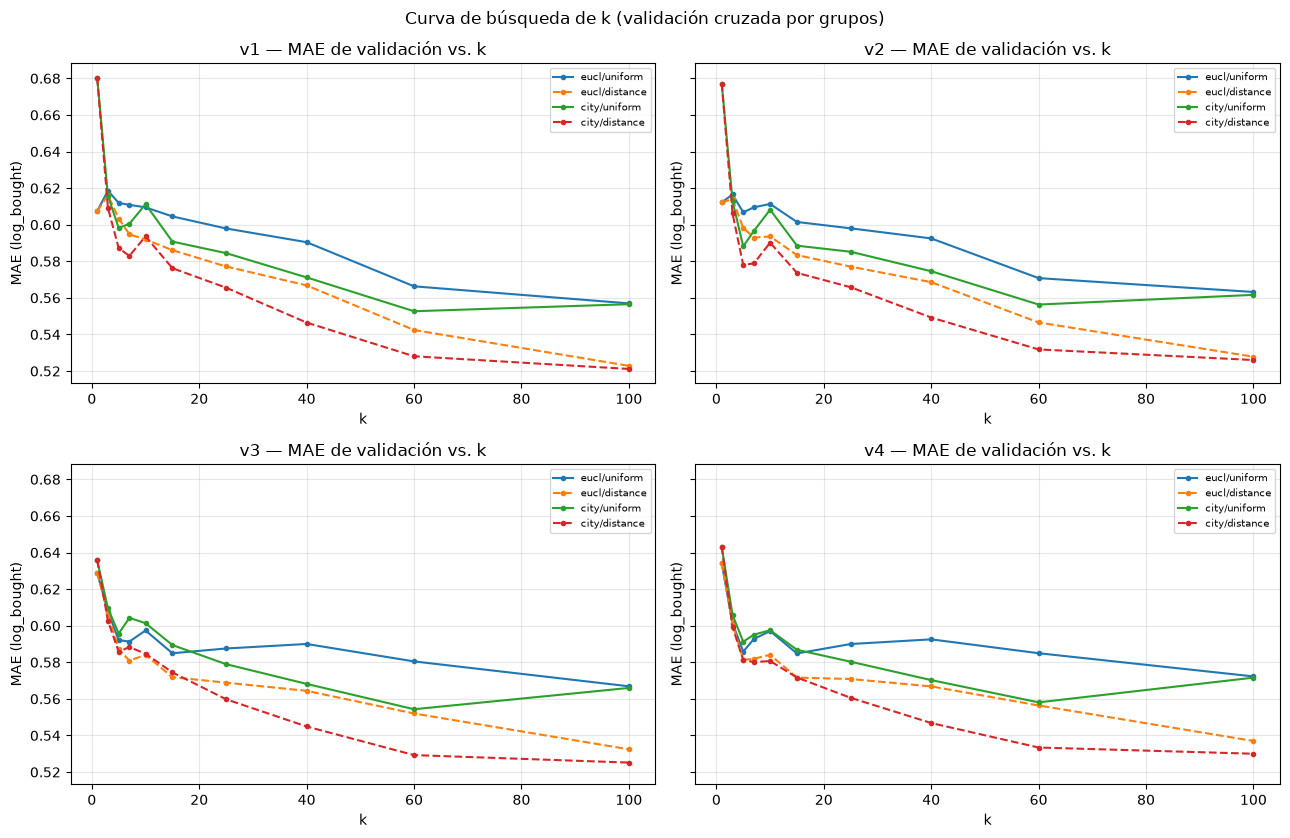

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8.5), sharey=True)
for ax, v in zip(axes.ravel(), (1, 2, 3, 4)):
    for m in METRICS:
        sub = grid_agg[(grid_agg["variante"] == f"v{v}") & (grid_agg["metric"] == m)]
        for w, ls in [("uniform", "-"), ("distance", "--")]:
            s2 = sub[sub["weights"] == w].sort_values("k")
            ax.plot(s2["k"], s2["MAE_media"], ls, marker="o", ms=3, label=f"{m[:4]}/{w}")
    ax.set_title(f"v{v} — MAE de validación vs. k")
    ax.set_xlabel("k")
    ax.set_ylabel("MAE (log_bought)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7)
plt.suptitle("Curva de búsqueda de k (validación cruzada por grupos)", fontsize=12)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "fig_k_vs_mae.png", dpi=120)
plt.show()

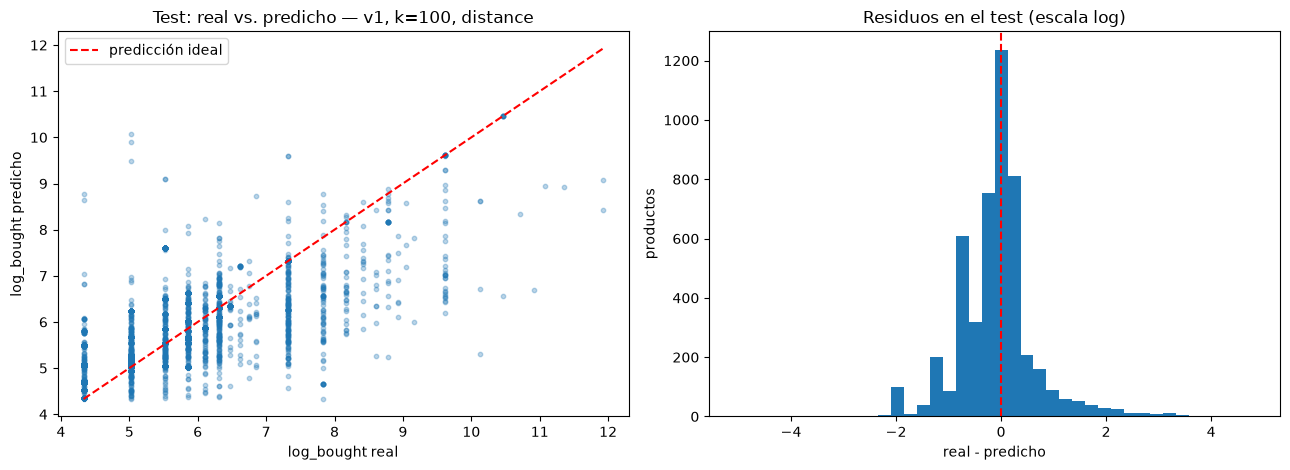

Residuo medio: -0.0900 | desviacion: 0.7564 | sesgo (predicho - real) medio: 0.0900


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

axes[0].scatter(y_test, y_pred_test, alpha=0.3, s=10)
lims = [min(y_test.min(), y_pred_test.min()), max(y_test.max(), y_pred_test.max())]
axes[0].plot(lims, lims, "r--", label="predicción ideal")
axes[0].set_xlabel("log_bought real")
axes[0].set_ylabel("log_bought predicho")
axes[0].set_title(f"Test: real vs. predicho — {sel_variant}, k={sel_k}, {sel_weights}")
axes[0].legend()

residuos = y_test - y_pred_test
axes[1].hist(residuos, bins=40)
axes[1].axvline(0, c="r", ls="--")
axes[1].set_title("Residuos en el test (escala log)")
axes[1].set_xlabel("real - predicho")
axes[1].set_ylabel("productos")

plt.tight_layout()
plt.savefig(RESULTS_DIR / "fig_test_real_vs_pred.png", dpi=120)
plt.show()

print(f"Residuo medio: {residuos.mean():.4f} | desviacion: {residuos.std():.4f} | "
      f"sesgo (predicho - real) medio: {(y_pred_test - y_test).mean():.4f}")

In [22]:
# Error en unidades por categoria de ventas (descriptivo del test; no se usa para decidir).
df_test = pd.DataFrame({
    "y_true_log": y_test,
    "y_pred_log": y_pred_test,
    "real_unidades": np.maximum(0, np.expm1(y_test)),
    "pred_unidades": np.maximum(0, np.expm1(y_pred_test)),
})
df_test["bought_cat"] = pd.cut(df_test["real_unidades"], bins=[0, 100, 200, 500, np.inf],
                               labels=["50-100", "101-200", "201-500", ">500"])
por_cat = df_test.groupby("bought_cat", observed=True).apply(
    lambda g: pd.Series({
        "n": len(g),
        "MAE_media_real_unidades": float(np.mean(np.abs(g["real_unidades"] - g["pred_unidades"]))),
        "MAPE_pct": mape(g["real_unidades"], g["pred_unidades"]),
        "sesgo_medio_unidades": float(np.mean(g["pred_unidades"] - g["real_unidades"])),
    }))
print("Error del test por categoría (solo descriptivo; el test no se usa para decidir):")
por_cat

Error del test por categoría (solo descriptivo; el test no se usa para decidir):


,n,MAE_media_real_unidades,MAPE_pct,sesgo_medio_unidades
bought_cat,,,,
50-100,765.0,94.883061,126.510748,94.883061
101-200,1326.0,109.785221,73.190147,104.178073
201-500,1655.0,248.211730,86.949250,150.463464
>500,1141.0,1561.624487,42.005642,-1379.410507


## 15. Comparacion con otros modelos del proyecto

Las metricas de este notebook usan test por grupos y preprocesamiento ajustado solo en train. No son
comparables directamente con resultados que hayan usado particion aleatoria o estadisticas globales
de imputacion/escalado; Random Forest y MLP deben reentrenarse con el mismo protocolo antes de una
comparacion final.


## 16. Conclusiones

Las tablas de arriba contienen los números. Los mensajes:

1. **La fuga era real y grande.** Con partición aleatoria, la mayor parte del test tiene un vecino a
   distancia 0 (fila de features idéntica) en train; el R² se infla. Al agrupar por contenido de las
   features, el R² es el de un KNN **honesto** (ver sección 4.1). Esta es la razón por la que una parte
   de los resultados previos del modelo KNN no se puede reportar tal cual.
2. **Las filas de precio imputado de v3/v4 sirven para entrenar, no para evaluar.** Al usarlas como
   refuerzo del entrenamiento, el error de validación cambia poco; como predictoras (lo que se hacía
   antes) el test se vuelve artificialmente fácil porque la *mediana de precio imputada* es una
   categoría reconocible y no un valor real.
3. **`delivery_cost` no aporta cuando se imputa con 0.** La comparación por parejas (sección 10.1) lo
   cuantifica. Imputar un costo desconocido con 0 confunde "envío gratis" con "envío no informado";
   v2/v4 sin la columna evitan una señal espuria.
4. **La elección de k no es crítica** una vez k es suficientemente grande: la curva MAE–k se aplana.
   k=1 tiene peor validación por memorizar, sobre todo en la parte ruidosa del espacio.
5. **Lo que el modelo *no* puede hacer:** predecir productos con menos de 50 compras al mes (no hay
   ejemplos de entrenamiento) ni ser más preciso que la discretización de las etiquetas de Amazon. Un
   R² modesto es esperable en este problema; lo útil es el MAE relativo (log) y el error en unidades por
   categoría.

## 17. Exportación de resultados

Se guardan, con el mismo estilo que `Models_Results/random_forest` y `Models_Results/mlp`:

| Archivo | Contenido |
|---|---|
| `metrics.json` | Configuración final, métricas en log y en unidades, tiempos, particiones. |
| `test_predictions.csv` | Predicciones del test común (log y unidades) y residuos. |
| `test_predictions_v3.csv` | Predicciones del test para las filas comunes de v3/v4 (mismas posiciones). |
| `hyperparameter_search.csv` | Rejilla completa (variante, distancia, k, pesos, fold y métricas). |
| `grid_agg.csv` | Resumen por configuración (media/std entre folds). |
| `results_summary.csv` | Una fila por variante con su configuración, MAE, IC, R², MAE/RMSLE en unidades y tiempos. |
| `split_indices.json` | Posiciones train/validation/test por variante (compatible con RF/MLP). |
| `knn_final.joblib` | Scaler + configuración elegida + (X, Y) de entrenamiento, listo para `predict`. |
| `fig_k_vs_mae.png`, `fig_test_real_vs_pred.png` | Gráficas de la sección 14. |
| `tiempos.json` | Tiempos de la rejilla. |

El joblib no guarda la matriz de distancias precalculada: se recomputa al predecir para mantener
coherencia con la función que se usó en los experimentos.

In [23]:
modelo_final = {
    "X_train": Xtrain_final,
    "Y_train": Ytrain_final,
    "k": int(sel_k),
    "weights": sel_weights,
    "metric": sel_metric,
}

metricas_payload = {
    "model": "KNN manual (cdist)",
    "target": TARGET,
    "variante": sel_variant,
    "configuracion": {"k": sel_k, "weights": sel_weights, "metric": sel_metric},
    "features": feats[sel_variant_id],
    "n_features": len(feats[sel_variant_id]),
    "random_state": SEED,
    "evaluacion": "test congelado antes de CV; grupos y escalado ajustado solo en train",
    "preprocesamiento": {
        "datasets": "dataset_v1.csv a dataset_v4.csv originales, compartidos con otros modelos",
        "imputacion": "medianas y limites precomputados en limpieza sobre todo el dataset; posible fuga",
        "escalado": "StandardScaler ajustado dentro de cada fold solo sobre train",
        "is_price_outlier_excluida": True,
    },
    "test_comun": {
        "filas_comunes": int(len(X1)),
        "filas_test": int(len(test_comun)),
        "filas_train_val": int(len(train_val_comun)),
        "filas_exclusivas_v3_v4_entrenamiento": int(n_exclusivas),
        "pct_test_con_gemelo_en_train": fraccion_con_gemelo(X1[train_val_comun], X1[test_comun]),
    },
    "metrics_log": {k: float(v) for k, v in metricas_log.items()},
    "metrics_unidades": {k: float(v) for k, v in metricas_unidades.items()},
    "baseline_mediana": {
        "MAE_log": float(baseline["MAE"].mean()),
        "RMSE_log": float(baseline["RMSE"].mean()),
        "R2_log": float(baseline["R2"].mean()),
    },
    "validation_by_variant": tabla_val_final.to_dict(orient="records"),
    "pairwise": df_pares.to_dict(orient="records"),
    "seconds_prediction_test": float(segundos_pred),
    "seconds_grid": float(segundos_total),
    "limitaciones": [
        "Se usan los datasets originales compartidos por todos los modelos.",
        "Las imputaciones y limites IQR globales previos a la particion pueden introducir fuga.",
        "El objetivo es el punto medio del intervalo reportado por Amazon.",
        "El test se limita a filas con precio observado para ser comun a las cuatro variantes.",
    ],
}
with open(RESULTS_DIR / "metrics.json", "w", encoding="utf-8") as f:
    json.dump(metricas_payload, f, indent=2, ensure_ascii=False)

predicciones = pd.DataFrame({
    "row_index": test_comun,
    "y_true_log": y_test,
    "y_pred_log": y_pred_test,
    "y_true_unidades": np.maximum(0, np.expm1(y_test)),
    "y_pred_unidades": np.maximum(0, np.expm1(y_pred_test)),
    "residual_log": y_test - y_pred_test,
})
predicciones.to_csv(RESULTS_DIR / "test_predictions.csv", index=False)

grid.to_csv(RESULTS_DIR / "hyperparameter_search.csv", index=False)
grid_agg.to_csv(RESULTS_DIR / "grid_agg.csv", index=False)

resumen = tabla_val_final.copy()
resumen["elegida_en_produccion"] = resumen["variante"] == sel_variant
resumen["baseline_MAE_log"] = float(baseline["MAE"].mean())
resumen["mejora_frente_a_baseline"] = resumen["baseline_MAE_log"] - resumen["MAE_val_media"]
resumen.to_csv(RESULTS_DIR / "results_summary.csv", index=False)

joblib.dump({
    "imputer": imputer_final,
    "scaler": scaler_final,
    "modelo": modelo_final,
    "variante": sel_variant_id,
    "features": feats[sel_variant_id],
    "configuracion": {"k": sel_k, "weights": sel_weights, "metric": sel_metric},
}, RESULTS_DIR / "knn_final.joblib")

with open(RESULTS_DIR / "tiempos.json", "w", encoding="utf-8") as f:
    json.dump({"grid_segundos_pared": float(segundos_total),
               "por_variante_fold": REGISTRO_TIEMPOS,
               "prediccion_test_segundos": float(segundos_pred)}, f, indent=2)

print("Resultados exportados en:", RESULTS_DIR.resolve().as_posix())
for archivo in sorted(RESULTS_DIR.iterdir()):
    print(" -", archivo.name, f"({archivo.stat().st_size / 1024:.1f} KB)")


Resultados exportados en: /home/barrera/Documentos/Udea/2026-2/Modelos y simulación/Trabajo de amazon/Amazon product sales/Modelos entrenados/Models_Results/knn
 - fig_k_vs_mae.png (200.0 KB)
 - fig_test_real_vs_pred.png (74.8 KB)
 - grid_agg.csv (28.4 KB)
 - hyperparameter_search.csv (81.7 KB)
 - knn_final.joblib (1987.1 KB)
 - metrics.json (5.2 KB)
 - results_summary.csv (1.1 KB)
 - split_indices.json (2332.2 KB)
 - test_predictions.csv (443.2 KB)
 - tiempos.json (1.1 KB)


## 18. Recarga del artefacto (comprobación)

El `.joblib` guarda los objetos de preprocesamiento y los datos/configuración del KNN como tipos
estándar, sin serializar clases definidas en el notebook. Se verifica la recarga y reproducción
exacta de las predicciones.

In [24]:
artefacto = joblib.load(RESULTS_DIR / "knn_final.joblib")
idx_test_model = mapa_row_id[artefacto["variante"]][test_comun]
Xult = Xv[artefacto["variante"]][idx_test_model]
Xult_imp = artefacto["imputer"].transform(Xult)
Xult_scaled = artefacto["scaler"].transform(Xult_imp)
modelo_recargado = artefacto["modelo"]
y_recargado, _ = knn_regresion(
    modelo_recargado["k"], modelo_recargado["X_train"], modelo_recargado["Y_train"],
    Xult_scaled, weights=modelo_recargado["weights"], metric=modelo_recargado["metric"]
)
print(f"Diferencia maxima frente a las predicciones de la seccion 13: "
      f"{float(np.max(np.abs(y_recargado - y_pred_test))):.3e}")
assert np.allclose(y_recargado, y_pred_test, atol=1e-10)
print("Artefacto recargado correctamente.")


Diferencia maxima frente a las predicciones de la seccion 13: 0.000e+00
Artefacto recargado correctamente.
